# Лабораторная работа №1
## Разведочный анализ данных: Titanic

**Выполнил:** Акимов Александр, гр. 4374 

---

**Цель работы:** провести разведочный анализ данных набора данных 
Titanic, выявить закономерности, определить ключевые признаки и подготовить 
данные для построения модели машинного обучения.

**Задача:** бинарная классификация — предсказать, выжил ли пассажир 

**Источник данных:** [Kaggle — Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic)

## 1. Загрузка данных и первичный обзор

Загружаем обучающую выборку и смотрим на её структуру.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# читаем датасет из файла и выводим его шапку
df = pd.read_csv('data/train.csv')
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1.1 Первичный обзор
Проверяем размеры датасета, типы данных признаков, целевую переменную

In [2]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


None

### Вывод:

**Структура данных:**
- **891 строка** — пассажиры обучающей выборки;
- **12 столбцов** — характеристики;
- **Целевая переменная:** `Survived` (0 / 1).

**Столбцы:**

| Столбец | Тип | Описание |
|---|---|---|
| `PassengerId` | int | ID пассажира |
| `Survived` | int | **Целевая**: 0 — погиб, 1 — выжил |
| `Pclass` | int | Класс билета |
| `Name` | str | Имя пассажира |
| `Sex` | str | Пол пассажира |
| `Age` | float | Возраст |
| `SibSp` | int | Количество братьев/сестёр + супругов |
| `Parch` | int | Количество родителей/детей |
| `Ticket` | str | Номер билета |
| `Fare` | float | Стоимость билета |
| `Cabin` | str | Номер каюты |
| `Embarked` | str | Порт посадки |

## 2. Разведочный анализ
**Подготавливаем данные для обучения:**
- проверка качества данных
- целевая переменная
- одномерный анализ
- двумерный анализ
- корреляции
- комбинированные признаки
- выводы

### 2.1 Проверка качества данных
Проверяем наличие:
- пропусков
- дубликатов
- аномалий

In [3]:
# Итоговая таблица пропусков
missing = {
    'Столбец': df.columns,
    'Пропусков': df.isnull().sum(),
    'Доля, %': (df.isnull().sum() / len(df)).round(3)
}

missing_df = pd.DataFrame(missing)
display(missing_df)

,Столбец,Пропусков,"Доля, %"
PassengerId,PassengerId,0,0.000
Survived,Survived,0,0.000
Pclass,Pclass,0,0.000
Name,Name,0,0.000
Sex,Sex,0,0.000
Age,Age,177,0.199
SibSp,SibSp,0,0.000
Parch,Parch,0,0.000
Ticket,Ticket,0,0.000
Fare,Fare,0,0.000


In [4]:
# оставим только столбцы с пропусками 
missing_df = missing_df[missing_df['Пропусков'] > 0]

# отсортируем по убыванию
missing_df = missing_df.sort_values('Пропусков', ascending=False)
display(missing_df)

,Столбец,Пропусков,"Доля, %"
Cabin,Cabin,687,0.771
Age,Age,177,0.199
Embarked,Embarked,2,0.002


#### Вывод по пропускам:
- Для `Cabin` > 75% пропусков - удаляем признак (мало информации)
- Для `Age` менее 25% пропусков - заполняем медианой
- Для `Embarked` менее 1% - заполняем модой (категориальный признак)

In [5]:
# провека дубликатов
print(f'Дубликатов: {df.duplicated().sum()}')

Дубликатов: 0


#### Вывод по дубликатам:
- дубликатов не обнаружено

#### Поиск аномальных значений:
Проверим отдельно **числовые** и **строковые** параметры.

Будем так же смотреть на кол-во **уникальных** значений параметра в поисках ошибок

In [6]:
# разделим признаки на числовые и строковые
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
str_cols = df.select_dtypes(include=['str']).columns

# проверка аномалий числовых значений
display(df[num_cols].describe().round(3))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000,891.000,891.000,714.000,891.000,891.000,891.000
mean,446.000,0.384,2.309,29.699,0.523,0.382,32.204
std,257.354,0.487,0.836,14.526,1.103,0.806,49.693
min,1.000,0.000,1.000,0.420,0.000,0.000,0.000
25%,223.500,0.000,2.000,20.125,0.000,0.000,7.910
50%,446.000,0.000,3.000,28.000,0.000,0.000,14.454
75%,668.500,1.000,3.000,38.000,1.000,0.000,31.000
max,891.000,1.000,3.000,80.000,8.000,6.000,512.329


In [7]:
# проверим уникальные значения
display(df[num_cols].nunique())

# выведем интересующие уникальные значения
for col in ['Survived', 'Pclass']:
    uniques = sorted(df[col].dropna().unique().tolist())
    print(f"{col}: уникальных = {uniques}")

PassengerId    891
Survived         2
Pclass           3
Age             88
SibSp            7
Parch            7
Fare           248
dtype: int64

Survived: уникальных = [0, 1]
Pclass: уникальных = [1, 2, 3]


#### Вывод по числовым параметрам:
- кол-во ID равно кол-ву наблюдений, в диапазоне от 1 до 891 - **без аномалий**
- кол-во уникальных значений `Survived` - 2: выжил или нет - **без аномалий**
- кол-во униклаьных значений `Pclass` - 3: 1й, 2й, 3й - **без аномалий**
- диапазон возраста от 0.42 до 80 лет - **без аномалий**
- кол-во родственников в пределах разумного значения - от 0 до 8 - **без аномалий**
- стоимость билетов разнится, но без аномальных значений - **без аномалий**

In [8]:
# проверка аномалий строковых значений
display(df[str_cols].nunique())

# выведем интересующие уникальные значения
for col in ['Sex', 'Embarked']:
    uniques = sorted(df[col].dropna().unique().tolist())
    print(f"{col}: уникальных = {uniques}")

Name        891
Sex           2
Ticket      681
Cabin       147
Embarked      3
dtype: int64

Sex: уникальных = ['female', 'male']
Embarked: уникальных = ['C', 'Q', 'S']


#### Вывод по строковым параметрам:
- кол-во имен равно кол-ву наблюдений - **без аномалий**
- кол-во уникальных значений `Sex` - 2: мужчина или женщина - **без аномалий**
- кол-во униклаьных значений `Embarked` - 3: C, Q, S - **без аномалий**

### 2.2. Целевая переменная

Целевая переменная — `Survived` (0 — погиб, 1 — выжил).

Проверим:
- распределение классов
- наличие дисбаланса

,Количество,"Доля, %"
Класс,,
0 (Погиб),549,61.62
1 (Выжил),342,38.38


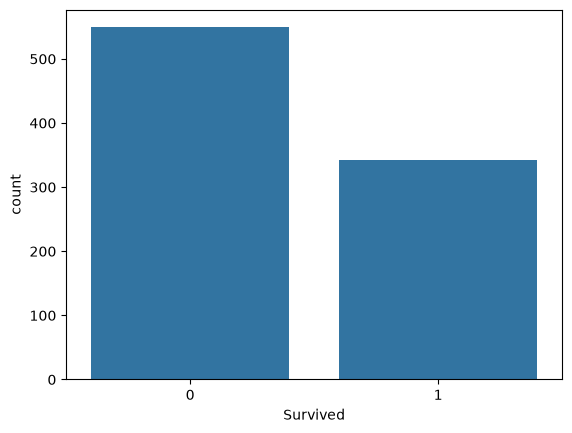

In [9]:
# распределение целевой переменной
counts = df['Survived'].value_counts()

# таблица распределения
survived_dist = {
    'Класс': ['0 (Погиб)', '1 (Выжил)'],
    'Количество': [counts[0], counts[1]],
    'Доля, %': [round(counts[0] / len(df) * 100, 2), round(counts[1] / len(df) * 100, 2)]
}

survived_df = pd.DataFrame(survived_dist)
survived_df = survived_df.set_index('Класс')
display(survived_df)

# график распределения
sns.countplot(data=df, x='Survived')
plt.show()

#### Вывод по целевой переменной:
Дисбаланс = 1.6 - **умеренный**

Для разделения на train/test необходима **стратификация**, чтобы сохранить пропорции классов.

### 2.3 Одномерный анализ

Изучаем каждый признак отдельно:
- распределение
- диапазон
- выбросы

#### **Числовые признаки** - `Age`, `Fare`, `SibSp`, `Parch`.

Изучаем каждый признак отдельно: 
- распределение
- диапазон
- выбросы

Построим для каждого признака по 2 диаграммы:
- гистограмма распределения (histplot + kde)
- диаграмма выбросов (boxplot)

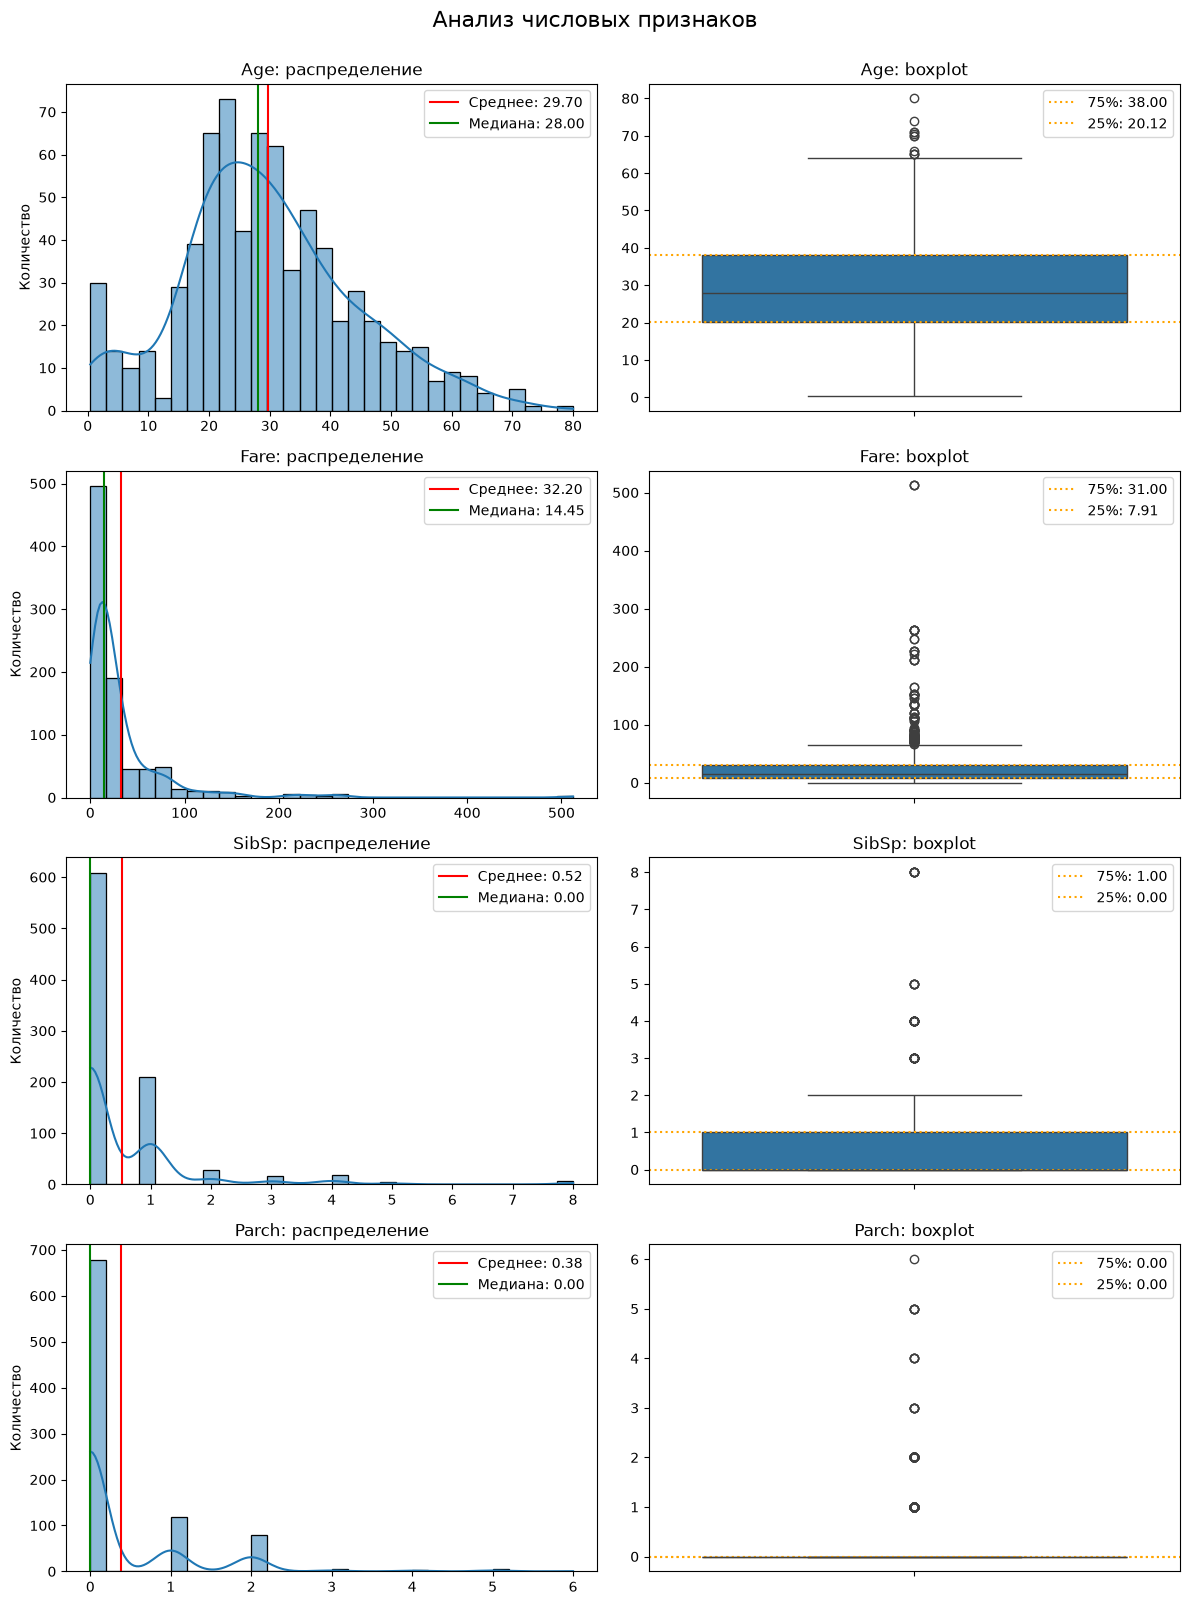

In [10]:
# Числовые признаки для анализа
numeric_cols = ['Age', 'Fare', 'SibSp', 'Parch']

# сетка графиков
fig, axes = plt.subplots(nrows=len(numeric_cols), ncols=2, figsize=(12, 4 * len(numeric_cols)))

# по 2 диаграммы для каждого признака
for i, col in enumerate(numeric_cols):

    # считаем статистики
    mean = df[col].mean()
    median = df[col].median()
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    
    # гистограмма распределения
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col}: распределение')
    axes[i, 0].set_xlabel('')
    axes[i, 0].set_ylabel('Количество')
    axes[i, 0].axvline(mean, color='red', label=f'Среднее: {mean:.2f}')
    axes[i, 0].axvline(median, color='green', label=f'Медиана: {median:.2f}')
    axes[i, 0].legend()
    
    # boxplot — выбросы и квартили
    sns.boxplot(data=df, y=col, ax=axes[i, 1])
    axes[i, 1].set_title(f'{col}: boxplot')
    axes[i, 1].set_ylabel('')
    axes[i, 1].axhline(q3, color='orange', linestyle=':', label=f'75%: {q3:.2f}')
    axes[i, 1].axhline(q1, color='orange', linestyle=':', label=f'25%: {q1:.2f}')
    axes[i, 1].legend()
    
plt.suptitle('Анализ числовых признаков', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

#### Выводы по числовым признакам

**Возраст:**
- **Форма:** распределение близко к нормальному, но слегка скошено вправо - основная масса людей в возрасте 20–40 лет, но есть «хвост» из пожилых людей.
- **Boxplot:** есть выбросы сверху - люди старше 65 лет.

**Стоимость билета:**
- **Форма:** распределение сильно скошено вправо - очень много дешевых билетов и очень мало дорогих.
- **Boxplot:** много выбросов сверху (дорогие билеты 1-го класса).

**Количество братьев/сестёр и родителей/детей:**
- **Форма:** распределения дискретные и сильно скошенные вправо. Большинство пассажиров ехали без родственников.
- **Boxplot:** ящик и усы нулевые. Все ненулевые значения (хотя бы один родственник) являются выбросами.

Для линейных моделей к `Fare` стоит применить **логарифмирование**, чтобы уменьшить влияние выбросов и приблизить распределение к нормальному.

#### **Категориальные признаки** — `Sex`, `Pclass`, `Embarked`.

Изучаем каждый признак отдельно:
- распределение категорий (сколько человек в каждой группе)
- дисбаланс классов

Построим для каждого признака по 1 диаграмме:
- столбиковая диаграмма (`countplot` с подписями количества и долей).


Признак: Sex


,Количество,"Доля, %"
Категория,,
male,577,64.76
female,314,35.24



Признак: Pclass


,Количество,"Доля, %"
Категория,,
3,491,55.11
1,216,24.24
2,184,20.65



Признак: Embarked


,Количество,"Доля, %"
Категория,,
S,644,72.28
C,168,18.86
Q,77,8.64


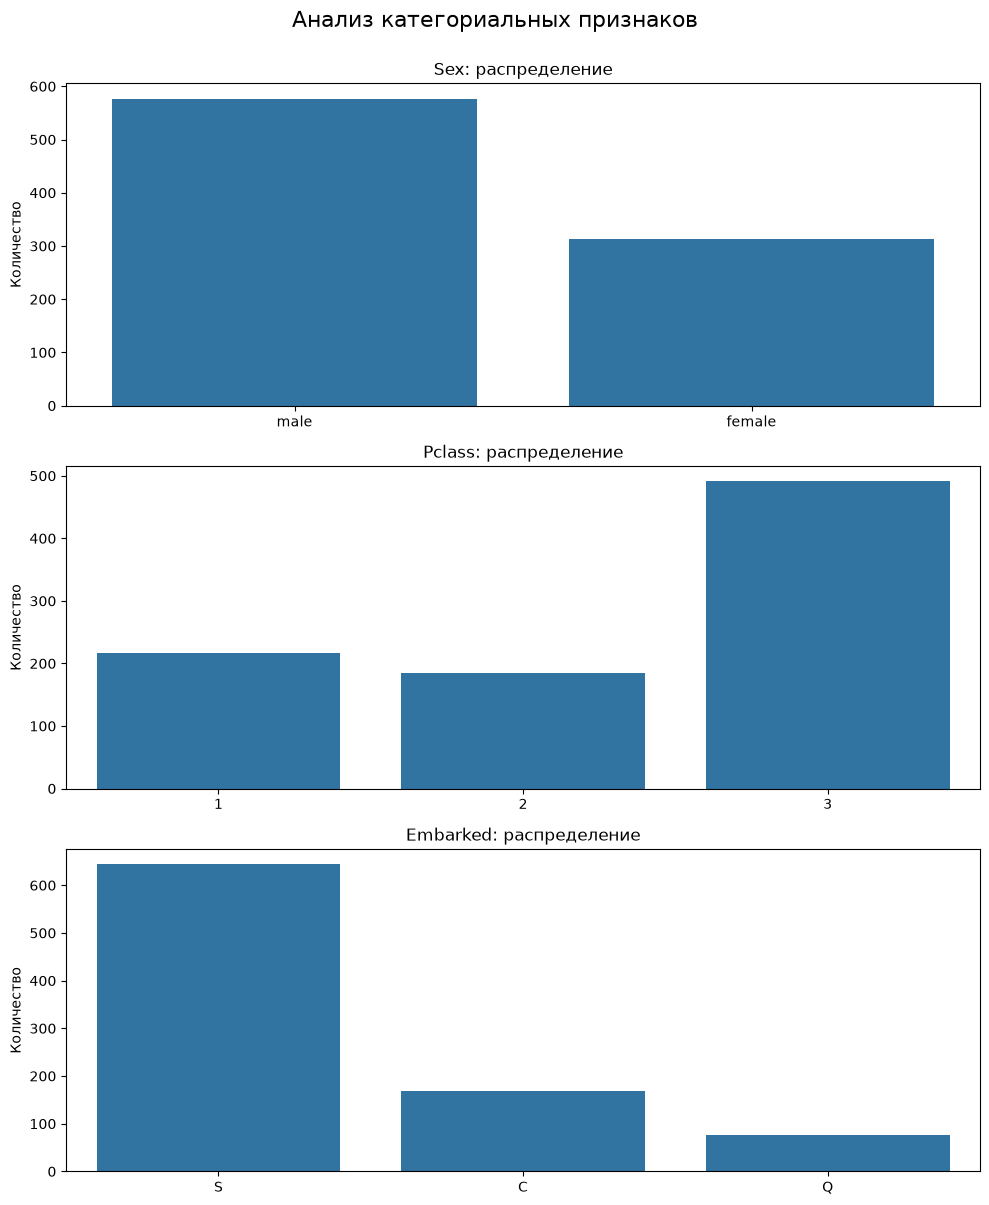

In [11]:
# категориальные признаки для анализа
categorical_cols = ['Sex', 'Pclass', 'Embarked']

for col in categorical_cols:
    
    # считаем частоты 
    counts = df[col].value_counts()
    
    # собираем данные
    data = {
        'Категория': counts.index.astype(str),
        'Количество': counts.values,
        'Доля, %': (counts.values / len(df) * 100).round(2)
    }
    
    # создаем DataFrame
    table = pd.DataFrame(data).set_index('Категория') 
    print(f"\nПризнак: {col}")
    display(table)

# сетка графиков
fig, axes = plt.subplots(nrows=len(categorical_cols), ncols=1, figsize=(10, 4 * len(categorical_cols)))

# по 1 диаграмме для каждого признака
for i, col in enumerate(categorical_cols):
    
    # строим countplot
    ax = sns.countplot(data=df, x=col, ax=axes[i])    
    axes[i].set_title(f'{col}: распределение', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Количество')

plt.suptitle('Анализ категориальных признаков', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

#### Выводы по категориальным признакам

**Пол:**
- В датасете мужчин почти в 2 раза больше, чем женщин - дисбаланс не критичный.

**Класс билета:**
- Распределение неравномерное: доминирует 3-й класс, меньше всего пассажиров 2-го класса.

**Порт посадки:**
- Большинство пассажиров сели в Саутгемптоне (`S`), значительно меньше в Шербуре (`C`) и Квинстауне (`Q`).

Признаки `Embarked` и `Sex` требуют **one-hot-encoding**.

### 2.4. Двумерный анализ

Изучаем связь каждого признака с целевой переменной `Survived`.

#### **Числовые признаки** - `Age`, `Fare`, `SibSp`, `Parch`.

Изучаем влияние признаков на выживаемость:
- Построим **boxplot** для сравнения медиан и разброса
- Построим **violinplot** для сравнения формы распределения

Средние значения по классам выживаемости:


,Age,Fare,SibSp,Parch
Survived,,,,
0,30.63,22.12,0.55,0.33
1,28.34,48.40,0.47,0.46


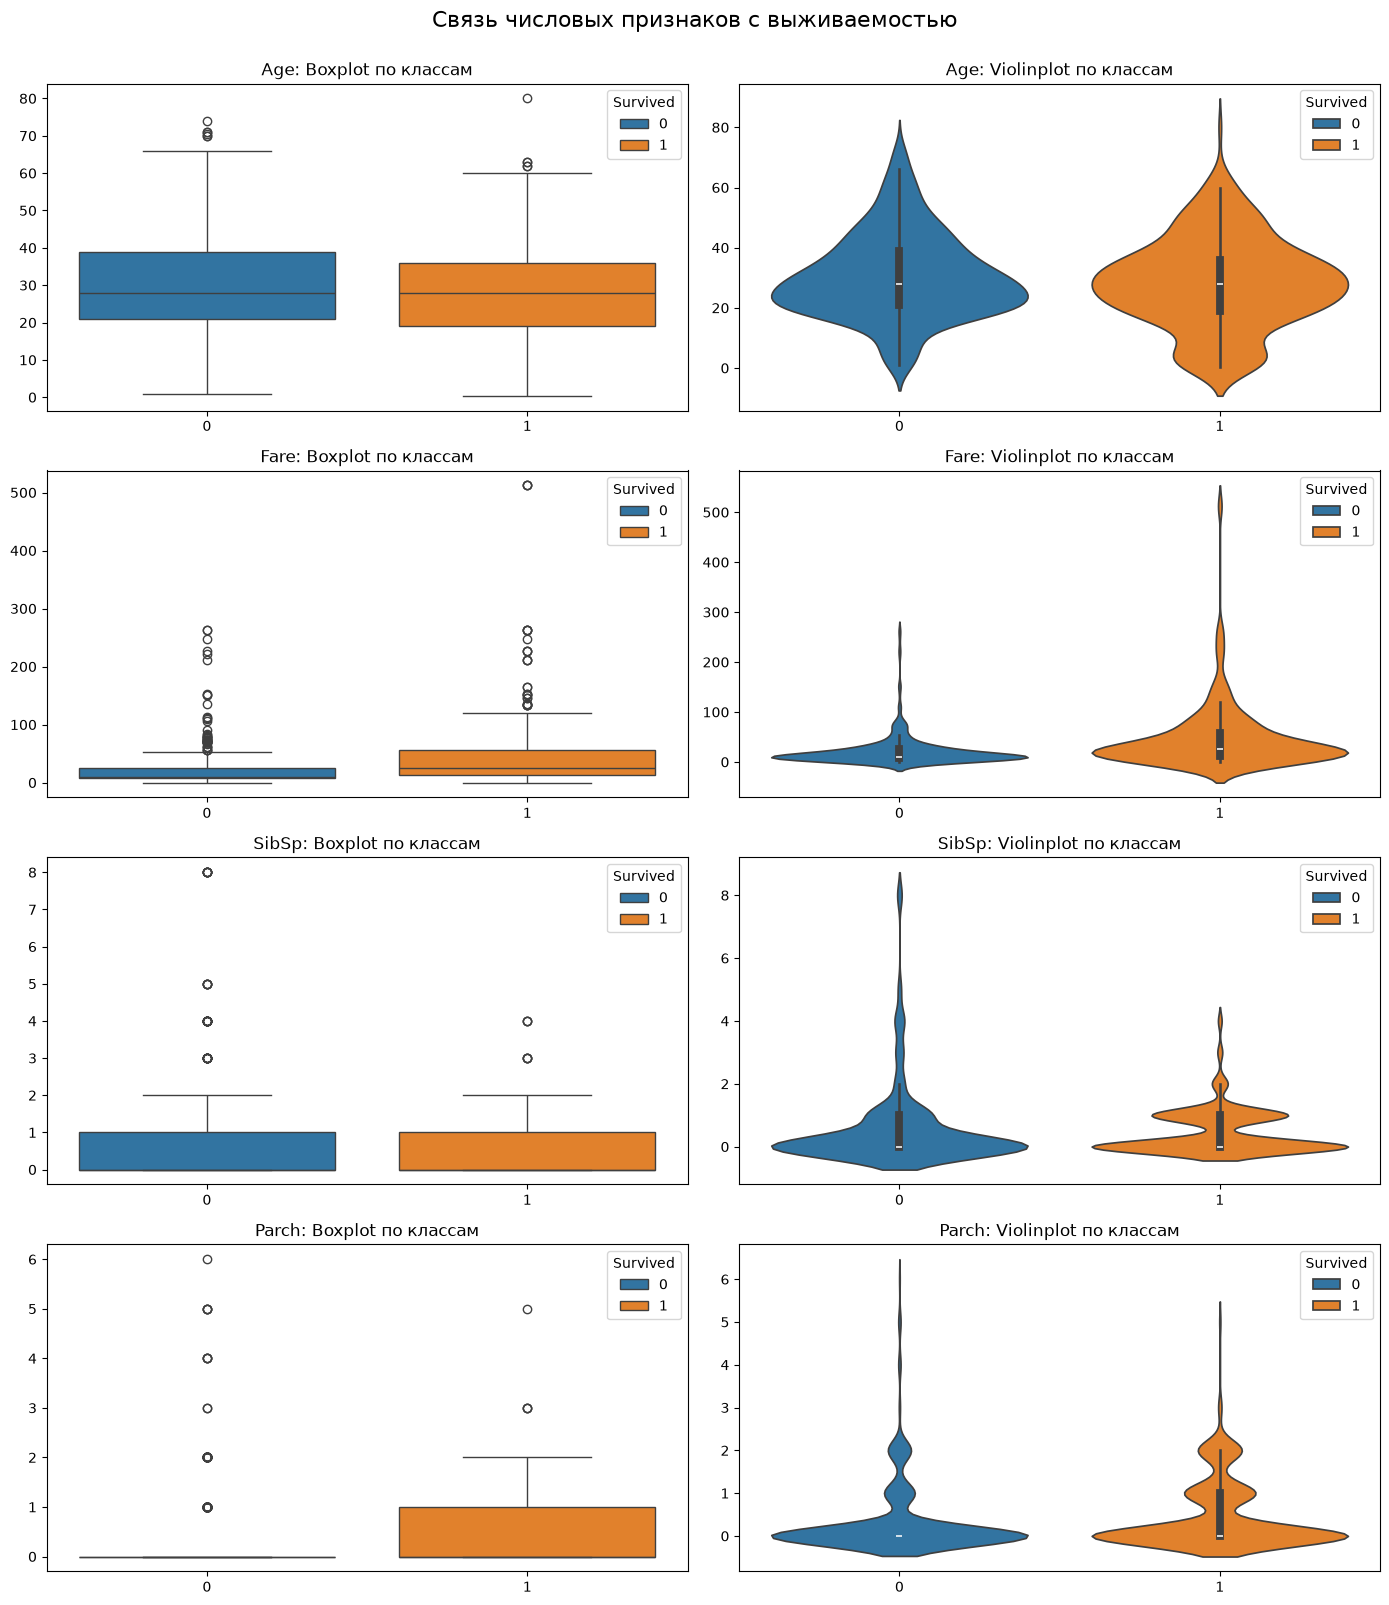

In [12]:
# cредние значения числовых признаков по классам выживаемости
summary = df.groupby('Survived')[numeric_cols].mean().round(2)
print("Средние значения по классам выживаемости:")
display(summary)

# графики 
fig, axes = plt.subplots(nrows=len(numeric_cols), ncols=2, figsize=(14, 4 * len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    
    # boxplot
    sns.boxplot(data=df, x='Survived', y=col, ax=axes[i, 0], hue='Survived')
    axes[i, 0].set_title(f'{col}: Boxplot по классам')
    axes[i, 0].set_xlabel('')
    axes[i, 0].set_ylabel('')
    
    # violinplot
    sns.violinplot(data=df, x='Survived', y=col, hue='Survived', ax=axes[i, 1])
    axes[i, 1].set_title(f'{col}: Violinplot по классам')
    axes[i, 1].set_xlabel('')
    axes[i, 1].set_ylabel('')

plt.suptitle('Связь числовых признаков с выживаемостью', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

#### Вывод по числовым признакам:

**Возраст:**
- Средний возраст выживших и погибших примерно одинаков.
- У выживших есть выраженный «второй пик» в области детей (0–10 лет).

**Стоимость билета:**
- Выжившие в среднем платили больше.

**Количество родственников:**
- У выживших чуть выше плотность в области значений 1–3. То есть люди с небольшой семьей выживали чаще, чем одиночки или люди с большими семьями.

`SibSp` и `Parch` лучше объединить в один признак `FamilySize`, т.к. они несут схожий смысл.

#### **Категориальные признаки** — `Sex`, `Pclass`, `Embarked`.

Изучаем влияние признаков на выживаемость:
- Построим **таблицы** и **диаграммы** с долями выживших


Выживаемость по признаку 'Sex':


,"Доля выживших, %"
Sex,
female,74.20
male,18.89



Выживаемость по признаку 'Pclass':


,"Доля выживших, %"
Pclass,
1,62.96
2,47.28
3,24.24



Выживаемость по признаку 'Embarked':


,"Доля выживших, %"
Embarked,
C,55.36
Q,38.96
S,33.70


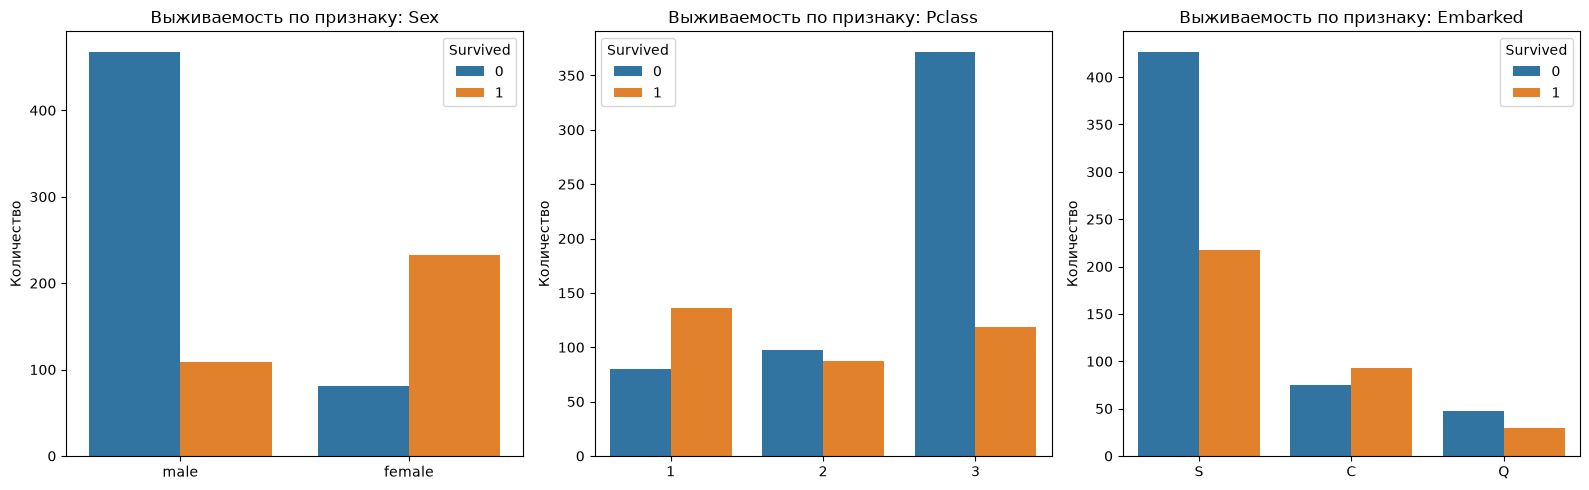

In [13]:
# таблицы с долями выживших
for col in categorical_cols:
    
    # считаем долю выживших
    survival_rate = (df.groupby(col)['Survived'].mean() * 100).round(2)
    
    # оформляем в DataFrame
    summary = survival_rate.reset_index()
    summary.columns = [col, 'Доля выживших, %']
    
    print(f"\nВыживаемость по признаку '{col}':")
    display(summary.set_index(col))

# графики
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))

for i, col in enumerate(categorical_cols):
    
    # countplot с разделением по Survived
    sns.countplot(data=df, x=col, hue='Survived', ax=axes[i])
    axes[i].set_title(f'Выживаемость по признаку: {col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Количество')

plt.tight_layout()
plt.show()

#### Вывод по категориальным признакам:

**Пол:**
- Женщины выживали намного чаще, чем мужчины.

**Класс билета:**
- Чем выше класс, тем выше выживаемость.

**Порт посадки:**
- Пассажиры из Шербура выживали чаще, но сама по себе зависимость выживаемости от порта логики не несет. Скорее всего это связано с зависимостью порта посадки от других признаков

### 2.5. Корреляционный анализ

Строим матрицу корреляций для числовых признаков - проверяем признаки на **зависимость** и **мультиколлинеарность**

Для анализа исключим бесполезный `PassengerId`, а категориальные `Sex` и `Embarked` временно закодируем, чтобы увидеть их связь с целевой переменной.

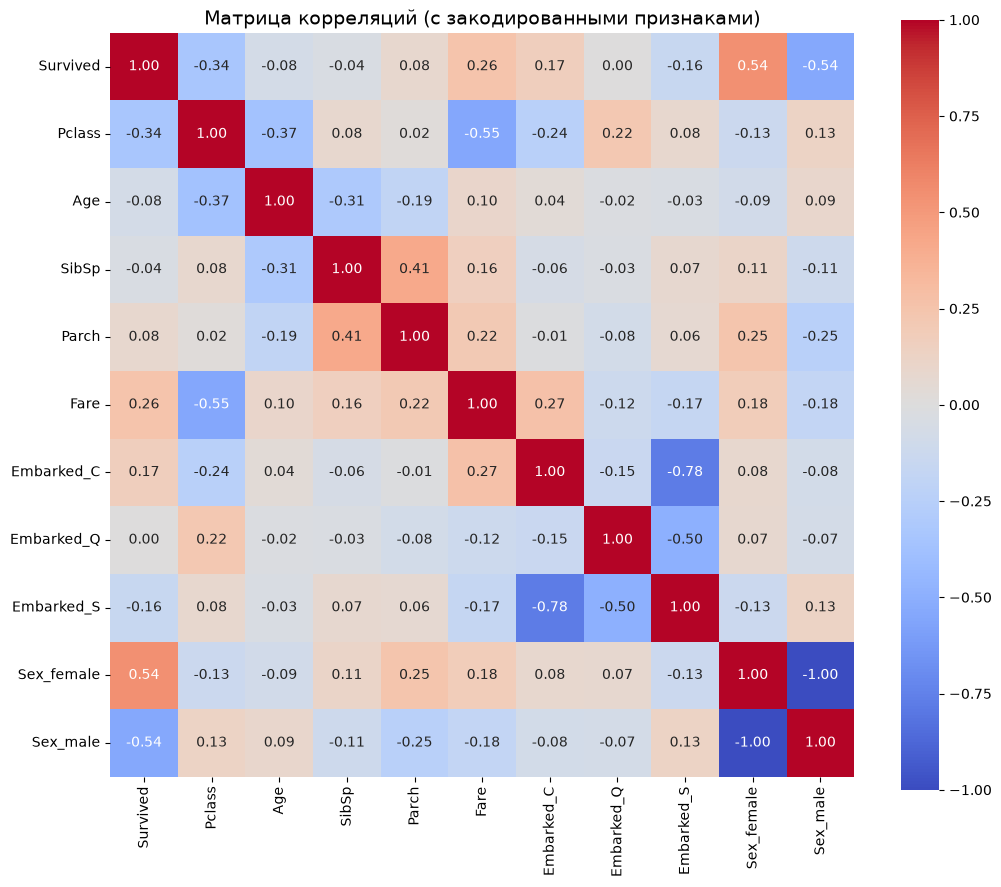

,Корреляция с Survived
Признак,
Sex_female,0.543
Fare,0.257
Embarked_C,0.168
Parch,0.082
Embarked_Q,0.004
SibSp,-0.035
Age,-0.077
Embarked_S,-0.156
Pclass,-0.338


In [14]:
# создаем копию для анализа
df_corr = df.copy()

# удаляем ID
df_corr = df_corr.drop(columns=['PassengerId'])

# кодируем Embarked и Sex (One-Hot Encoding)
df_corr = pd.get_dummies(df_corr, columns=['Embarked', 'Sex'])

# cчитаем корреляцию только для числовых столбцов
corr_matrix = df_corr.select_dtypes(include=['int64', 'float64', 'bool']).corr()

# cтроим тепловую карту
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Матрица корреляций (с закодированными признаками)', fontsize=14)
plt.show()

# выводим корреляции с целевой переменной в виде таблицы
survived_corr = corr_matrix['Survived'].drop('Survived').sort_values(ascending=False)
corr_df = pd.DataFrame({
    'Признак': survived_corr.index,
    'Корреляция с Survived': survived_corr.values.round(3)
}).set_index('Признак')

display(corr_df)

#### Вывод по корреляциям:

**Связь с целевой переменной:**
- `Sex_female` — **сильнейшая** положительная корреляция. Женщины имели значительно больше шансов на спасение. Мужчины - наоборот.
- `Pclass` — **сильная** отрицательная корреляция. Чем больше номер класса, тем ниже шанс выжить.
- `Fare` — **умеренная** положительная корреляция. Чем дороже билет, тем выше шанс выжить.
- `Embarked_C` (порт Шербур) — **слабая** положительная связь. Пассажиры из этого порта чаще выживали.
- Остальные признаки имеют **очень слабую связь** с выживаемостью.

**Мультиколлинеарность (связи между признаками):**
- `Pclass` и `Fare` — **сильная** отрицательная связь. Билеты 1-го класса стоят дорого, 3-го — дешево.
- `SibSp` и `Parch` — **умеренная** положительная связь. если человек едет с семьей, оба парамета больше 0.
- `Embarked_C` и `Pclass` — **умеренная** отрицательная связь. Пассажиры из Шербура чаще покупали билеты 1-го класса.

**Итог:** 
- Признак `Sex` имеет самое сильное влияние на выживаемость.
- Из-за мультиколлинеарности `Pclass` и `Fare` для линейных моделей потребуется **отбор признаков**.
- Из-за парной связи `SibSp` и `Parch`, для линейных моделей потребуется **объединение** признаков.

### 2.6. Комбинированные признаки

Проверяем, дают ли комбинации признаков больше информации, чем отдельные признаки.

#### Логика комбинирования признаков

При создании новых признаков были выбраны следующие комбинации:

**`FamilySize` (Размер семьи) — объединение `SibSp` и `Parch`**
- **Причина:** В корреляционном анализе мы выявили умеренную положительную связь между `SibSp` и `Parch`. Оба признака описывают одно и то же — наличие семьи, но с разных сторон. Если оставить их оба, для линейных моделей возникнет проблема мультиколлинеарности.
- **Решение:** Сложить их в один признак `FamilySize = SibSp + Parch + 1`. Единица добавляется, чтобы учесть самого пассажира.

**`Sex_Pclass` (Пол + Класс) — взаимодействие двух сильных признаков**
- **Причина:** `Sex` и `Pclass` показали самую сильную связь с выживаемостью.
- **Решение:** Объединить их в строковый признак, затем закодировать.

Выживаемость по размеру семьи:


,"Доля выживших, %"
FamilySize,
1,30.35
2,55.28
3,57.84
4,72.41
5,20.00
6,13.64
7,33.33
8,0.00
11,0.00



Выживаемость по комбинации Пол + Класс:


,"Доля выживших, %"
Sex_Pclass,
female_1,96.81
female_2,92.11
female_3,50.00
male_1,36.89
male_2,15.74
male_3,13.54


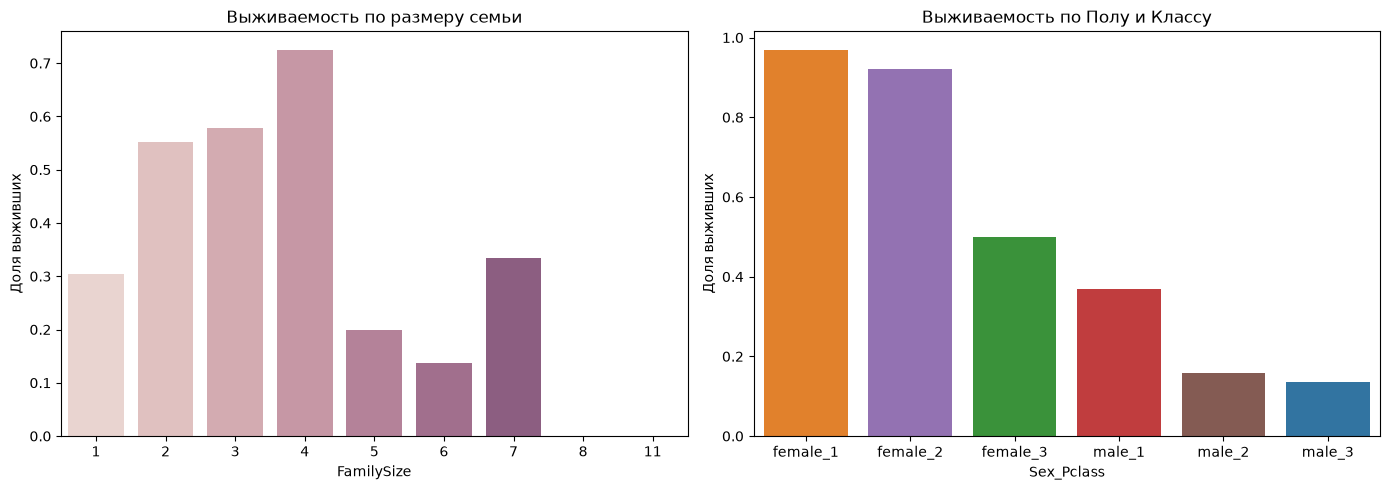

In [15]:
# создаем комбинированные признаки
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['Sex_Pclass'] = df['Sex'] + '_' + df['Pclass'].astype(str)

# анализ FamilySize
print("Выживаемость по размеру семьи:")
family_survival = (df.groupby('FamilySize')['Survived'].mean() * 100).round(2)
display(family_survival.to_frame('Доля выживших, %'))

# анализ Sex_Pclass
print("\nВыживаемость по комбинации Пол + Класс:")
sex_pclass_survival = (df.groupby('Sex_Pclass')['Survived'].mean() * 100).round(2).sort_values(ascending=False)
display(sex_pclass_survival.to_frame('Доля выживших, %'))

# графики
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# barplot для FamilySize
sns.barplot(data=df, x='FamilySize', y='Survived', hue='FamilySize', ax=axes[0], errorbar=None, legend=False)
axes[0].set_title('Выживаемость по размеру семьи')
axes[0].set_ylabel('Доля выживших')

# barplot для Sex_Pclass
sns.barplot(data=df, x='Sex_Pclass', y='Survived', order=sex_pclass_survival.index, hue='Sex_Pclass', ax=axes[1], errorbar=None, legend=False)
axes[1].set_title('Выживаемость по Полу и Классу')
axes[1].set_ylabel('Доля выживших')

plt.tight_layout()
plt.show()

#### Вывод по комбинированным признакам:

**Размер семьи:**
- Пассажиры, путешествующие в одиночку, выживали в 30% случаев.
- Пассажиры с небольшой семьей выживали чаще всего.
- Пассажиры с большими семьями почти не спасались.

**Комбинация Пол + Класс:**
- Наивысший процент выживания у женщин 1-го и 2-го классов.
- Женщины 3-го класса выживали в 50% случаев.
- Мужчины 1-го класса - 37%, мужчины 3-го класса - всего 14%.
 
Комбинированные признаки несут больше информации, чем исходные. Признак `FamilySize` лучше заменит `SibSp` и `Parch`, а `Sex_Pclass` покажет скрытые закономерности. Эти признаки нужно будет создать на этапе **Feature Engineering**.

### 2.7. Выводы по EDA

На основе проведенного разведочного анализа данных можно сделать следующие выводы о датасете и рекомендации для дальнейшего моделирования.

#### 1. Качество данных
- **Пропуски:** `Cabin` (77%) — удалить; `Age` (20%) — заполнить медианой; `Embarked` (0.2%) — заполнить модой.
- **Дубликаты:** отсутствуют.
- **Аномалии:** в числовых признаках не обнаружено критичных ошибок. Выбросы в `Fare` и `Age` являются реальными значениями.

#### 2. Целевая переменная
- `Survived` имеет умеренный дисбаланс (62% / 38%). 
- Для разделения на train/test обязательна **стратификация**.

#### 3. Ключевые признаки
1. `Sex` - сильнейший признак (женщины выживают чаще).
2. `Pclass` - сильный признак (1 класс выживает чаще).
3. `Fare` - связан с `Pclass` (дорогие билеты = 1 класс = выше шанс).
4. `Age` - дети выживали чаще, но в целом связь слабая.
5. `Embarked` - слабая связь (порт `C` выживал чаще, но это, скорее всего, связано с классом).

#### 4. Рекомендации по подготовке данных (Feature Engineering)
- **Удалить:** `PassengerId`, `Name`, `Ticket`, `Cabin`.
- **Заполнить пропуски:** `Age` (медиана), `Embarked` (мода).
- **Создать новые признаки:** 
    - `FamilySize` = `SibSp` + `Parch` + 1 (заменит два исходных).
    - `Sex_Pclass` - комбинация пола и класса
- **Закодировать:**
    - `Sex` (Label Encoding: male=0, female=1)
    - `Embarked` и `Sex_Pclass` (One-Hot Encoding).
- **Трансформировать:** для линейных моделей применить логарифмирование к `Fare`.
- **Отбор признаков:** для линейных моделей удалить `Fare` или `Pclass` (из-за мультиколлинеарности), а `SibSp` и `Parch` заменить на `FamilySize`.

## 3. Feature Engineering (Подготовка данных)

**На основе EDA выполним подготовку данных:**
- Обработка пропусков и удаление лишних признаков
- Создание новых признаков
- Кодирование категориальных признаков

### 3.1. Обработка пропусков и удаление ненужных столбцов

**Удаляем:**
- `PassengerId` — уникальный ID, не несёт информации для модели.
- `Ticket` — беспорядочный номер, не коррелирует с выживаемостью.
- `Cabin` — 77% пропусков, и сам признак не несет полезной информации
- `Name` — уникален для каждого пассажира, не несет полезной информации.

**Заполняем пропуски:**
- `Age` (20% пропусков) заполняем **медианой** (устойчива к выбросам и скошенности).
- `Embarked` (2 пропуска) заполняем **модой** (категориальный признак).


In [16]:
# удаляем столбцы с ненужными признаками
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# заполняем Age и Embarked
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [17]:
# проверяем результат
display(df.info())
print(f'\nПропусков:{df.isnull().sum()}')

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    str    
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   Embarked    891 non-null    str    
 8   FamilySize  891 non-null    int64  
 9   Sex_Pclass  891 non-null    str    
dtypes: float64(2), int64(5), str(3)
memory usage: 80.5 KB


None


Пропусков:Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
Sex_Pclass    0
dtype: int64


### 3.2. Создание новых признаков

**Создаем признаки:**
- `FamilySize` - объединение `Parch` и `SibSp`.
- `Sex_Pclass` - объединение `Sex` и `Pclass`.
- `Fare_log` - логарифм от `Fare` - сжимает выбросы и приближает распределение к нормальному.

Создадим эти признаки и удалим исходные `Fare`, `SibSp` и `Parch`, чтобы избежать мультиколлинеарности.

In [18]:
# создаем признаки
df['FamilySize'] = df['Parch'] + df['SibSp'] + 1
df['Sex_Pclass'] = df['Sex'] + '_' + df['Pclass'].astype(str)
df['Fare_log'] = np.log1p(df['Fare'])

# удаляем ненужные столбцы
df = df.drop(columns=['Fare', 'Parch', 'SibSp'])

In [19]:
# проверяем результат
display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    str    
 3   Age         891 non-null    float64
 4   Embarked    891 non-null    str    
 5   FamilySize  891 non-null    int64  
 6   Sex_Pclass  891 non-null    str    
 7   Fare_log    891 non-null    float64
dtypes: float64(2), int64(3), str(3)
memory usage: 66.6 KB


None

,Survived,Pclass,Sex,Age,Embarked,FamilySize,Sex_Pclass,Fare_log
0,0,3,male,22.0,S,2,male_3,2.110213
1,1,1,female,38.0,C,2,female_1,4.280593
2,1,3,female,26.0,S,1,female_3,2.188856
3,1,1,female,35.0,S,2,female_1,3.990834
4,0,3,male,35.0,S,1,male_3,2.202765


### 3.3. Кодирование категориальных признаков

**Кодируем признаки:**
- `Sex` через Label Encoding
- `Embarked` и `Sex_Pclass` через One-Hot Encoding

In [20]:
# кодируем Sex
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# кодируем Embarked и Sex_Pclass, удаляя исходные столбцы
df = pd.get_dummies(data=df, columns=['Embarked', 'Sex_Pclass'], drop_first=False)

In [21]:
# проверяем результат
display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Survived             891 non-null    int64  
 1   Pclass               891 non-null    int64  
 2   Sex                  891 non-null    int64  
 3   Age                  891 non-null    float64
 4   FamilySize           891 non-null    int64  
 5   Fare_log             891 non-null    float64
 6   Embarked_C           891 non-null    bool   
 7   Embarked_Q           891 non-null    bool   
 8   Embarked_S           891 non-null    bool   
 9   Sex_Pclass_female_1  891 non-null    bool   
 10  Sex_Pclass_female_2  891 non-null    bool   
 11  Sex_Pclass_female_3  891 non-null    bool   
 12  Sex_Pclass_male_1    891 non-null    bool   
 13  Sex_Pclass_male_2    891 non-null    bool   
 14  Sex_Pclass_male_3    891 non-null    bool   
dtypes: bool(9), float64(2), int64(4)
memory usage: 49.7

None

,Survived,Pclass,Sex,Age,FamilySize,Fare_log,Embarked_C,Embarked_Q,Embarked_S,Sex_Pclass_female_1,Sex_Pclass_female_2,Sex_Pclass_female_3,Sex_Pclass_male_1,Sex_Pclass_male_2,Sex_Pclass_male_3
0,0,3,0,22.0,2,2.110213,False,False,True,False,False,False,False,False,True
1,1,1,1,38.0,2,4.280593,True,False,False,True,False,False,False,False,False
2,1,3,1,26.0,1,2.188856,False,False,True,False,False,True,False,False,False
3,1,1,1,35.0,2,3.990834,False,False,True,True,False,False,False,False,False
4,0,3,0,35.0,1,2.202765,False,False,True,False,False,False,False,False,True


### Вывод по Feature Engineering:
- Датасет очищен, все признаки имеют числовой тип, созданы осмысленные комбинации. 
- Данные готовы к разделению на train/test и обучению моделей.

## 4. Разделение данных на train и test

Разделим данные на две части:
- **Обучающая выборка (train)** — 80% данных. На ней модель ищет закономерности.
- **Тестовая выборка (test)** — 20% данных. Используется  для проверки модели.

Применяем **стратификацию** чтобы сохранить пропорции классов в выборках.

Разделение происходит до стандартизации, чтобы избежать **утечки данных**.

In [22]:
from sklearn.model_selection import train_test_split

# отделяем целевую переменную
X = df.drop(columns=['Survived'])
y = df['Survived']

# разделяем данные со стратификацией
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# создаем данные для таблицы
data = {
    'Датасет': ['Весь датасет', 'Train (80%)', 'Test (20%)'],
    'Всего пассажиров': [len(y), len(y_train), len(y_test)],
    'Погибли': [y.value_counts()[0], y_train.value_counts()[0], y_test.value_counts()[0]],
    'Выжили': [y.value_counts()[1], y_train.value_counts()[1], y_test.value_counts()[1]],
}
split_summary = pd.DataFrame(data)

# добавляем долю выживших
split_summary['Доля выживших, %'] = (split_summary['Выжили'] / split_summary['Всего пассажиров'] * 100).round(2)
split_summary = split_summary.set_index('Датасет')
display(split_summary)

,Всего пассажиров,Погибли,Выжили,"Доля выживших, %"
Датасет,,,,
Весь датасет,891,549,342,38.38
Train (80%),712,439,273,38.34
Test (20%),179,110,69,38.55


**Вывод:** 
Разница пропорций мала - пропорции классов сохранены.

## 5. Обучение моделей

**Выбор моделей для сравнения:**

Для классификации выбраны две модели, представляющие разные подходы:

**1. Логистическая регрессия:**
- Линейная модель — базовая для сравнения.
- Интерпретируемая — коэффициенты показывают влияние признаков.
- Быстро обучается — много экспериментов.
- Требует **стандартизации** и удаления **мультиколлинеарных** признаков (`Fare_log`, `Embarked`).

**2. Дерево решений:**
- Нелинейная модель — улавливает взаимодействия (`Sex × Pclass`).
- Устойчива к **выбросам** и **мультиколлинеарности**.
- Интерпретируемая — можно визуализировать дерево.
- Не требует стандартизации.
- Ограничение `max_depth` — защита от **переобучения**.

В итоге сравним подход и увидим природу данных (линейная или нелинейная)

### 5.1. Логистическая регрессия

Логистическая регрессия — базовая линейная модель для бинарной классификации. Она вычисляет вероятность выживания на основе линейной комбинации признаков, пропущенной через сигмоиду (для нормализации результата).

**Подготовка данных:**
- Пробуем исключать разные корррелирующие признаки для лучшей точности.
- Применяем **StandardScaler** для масштабирования данных.
- Обучаем инструмент для масштабирования только на тренировочной выборке.
- К тестовой выборке применяем уже масштабированные параметры, чтобы избежать **утечки данных**.

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# отбираем признаки для линейной модели
features_linear = [col for col in X_train.columns if col in ['Pclass', 'Sex', 'Age', 'FamilySize', 'Fare_log']]
print(f'Признаки: {features_linear}')
X_train_linear = X_train[features_linear]
X_test_linear = X_test[features_linear]

# масштабируем
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_linear)
X_test_scaled = scaler.transform(X_test_linear)

# обучаем модель
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# делаем предсказания
y_pred_log = log_reg.predict(X_test_scaled)
y_proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]

print(f"Обучено на {len(features_linear)} признаках.")

Признаки: ['Pclass', 'Sex', 'Age', 'FamilySize', 'Fare_log']
Обучено на 5 признаках.


### 5.2. Дерево решений

Дерево решений — нелинейная модель, которая разбивает данные на основе пороговых значений признаков. Оно **не требует масштабирования** и **устойчиво к мультиколлинеарности**. 

Так же будем подбирать разные признаки для лучшей точности.

Для ограничения переобучения зададим `max_depth` (максимальная глубина дерева).

In [24]:
from sklearn.tree import DecisionTreeClassifier

# отбираем признаки для дерева
features_tree = [col for col in X_train.columns if col not in ['Pclass', 'Embarked_C', 'Embarked_Q', 'Embarked_S']]
print(f'Признаки: {features_tree}')
X_train_tree = X_train[features_tree]
X_test_tree = X_test[features_tree]

# обучаем дерево
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train_tree, y_train)

# делаем предсказания
y_pred_tree = tree_model.predict(X_test_tree)
y_proba_tree = tree_model.predict_proba(X_test_tree)[:, 1]

print(f"Обучено на {len(features_tree)} признаках.")

Признаки: ['Sex', 'Age', 'FamilySize', 'Fare_log', 'Sex_Pclass_female_1', 'Sex_Pclass_female_2', 'Sex_Pclass_female_3', 'Sex_Pclass_male_1', 'Sex_Pclass_male_2', 'Sex_Pclass_male_3']
Обучено на 10 признаках.


### Вывод по обучению моделей

Для решения задачи были обучены две модели: **логистическая регрессия** и **дерево решений**.

Следующим этапом будет анализ результатов и выбор лучших **признаков** и **параметров** для моделей.